### Practica 3 - RA1
**Alumno** : Gabriel Herrador
**Modulo** : M3 - Programació d'inteligencia artificial

### 1. Entorno, versiones y carga de librerías
Registramos las versiones de Python y de las bibliotecas utilizadas para asegurar la trazabilidad y reproducibilidad del experimento.

In [2]:
import platform
import sys
import time
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

t_inicio = time.perf_counter()

print(f"Python: {sys.version.split()[0]} | SO: {platform.platform()}")
print(f"pandas: {pd.__version__} | numpy: {np.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"matplotlib: {matplotlib.__version__} | seaborn: {sns.__version__}")

Matplotlib is building the font cache; this may take a moment.


Python: 3.14.5 | SO: Windows-11-10.0.26200-SP0
pandas: 3.0.6 | numpy: 2.5.3
scikit-learn: 1.9.1
matplotlib: 3.11.2 | seaborn: 0.13.2


### 2. Carga del dataset Iris y exploración inicial
Cargamos el dataset Iris completo, revisamos su estructura (`filas x columnas`), comprobamos los tipos de datos de cada variable y observamos cómo se representa la especie objetivo.

In [3]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()

# Añadimos el nombre legible de la especie además del índice numérico 'target'
mapa_clases = dict(enumerate(iris.target_names))
df["species"] = df["target"].map(mapa_clases)

print("Forma del dataset (filas, columnas):", df.shape)
print("\nPrimeras filas:")
display(df.head())

print("\nInformación general y tipos de datos:")
df.info()

print("\nDistribución de la clase (species):")
print(df["species"].value_counts())

Forma del dataset (filas, columnas): (150, 6)

Primeras filas:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa



Información general y tipos de datos:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 8.4 KB

Distribución de la clase (species):
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


### 3. Partición estratificada (80/20, semilla 42) y estandarización
Dividimos los datos de forma estratificada en un 80 % para entrenamiento y un 20 % para prueba con `random_state=42`, y estandarizamos las variables ajustando el escalador solo en entrenamiento para evitar fuga de datos (*data leakage*).

In [4]:
X = df[iris.feature_names]
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42,
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Muestras de entrenamiento: {X_train_scaled.shape[0]}")
print(f"Muestras de prueba: {X_test_scaled.shape[0]}")

Muestras de entrenamiento: 120
Muestras de prueba: 30


### 4. Entrenamiento del modelo KNN ($k=5$) y evaluación
Entrenamos el clasificador KNN con `n_neighbors=5`, medimos el tiempo de ejecución y calculamos las métricas mínimas exigidas: **accuracy** y **matriz de confusión**.

In [5]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)
t_fin = time.perf_counter()

acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred, labels=iris.target_names)
tiempo_total_ms = (t_fin - t_inicio) * 1000

print(f"Accuracy (k=5): {acc:.4f} ({acc*100:.2f}%)")
print(f"Tiempo total de ejecución aproximado: {tiempo_total_ms:.2f} ms")
print("\nMatriz de confusión (filas = real, columnas = predicción):")
print(cm)
print("\nDetalle por clase:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Accuracy (k=5): 0.9333 (93.33%)
Tiempo total de ejecución aproximado: 354838.02 ms

Matriz de confusión (filas = real, columnas = predicción):
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

Detalle por clase:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



### 5. Visualización de resultados y dependencias externas
Representamos gráficamente la matriz de confusión para facilitar la interpretación visual de los aciertos y errores del modelo, e identificamos qué partes del código dependen de bibliotecas externas.

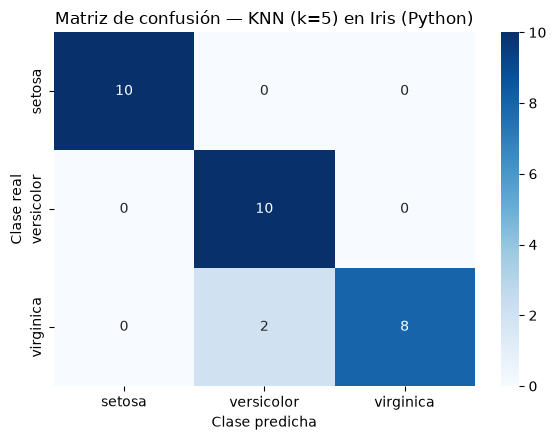

In [6]:
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names,
    ax=ax,
)
ax.set_title("Matriz de confusión — KNN (k=5) en Iris (Python)")
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
plt.tight_layout()
plt.show()